# S2 — profile: news for land ads (workstream B)
Read-only, **remote** profile (DuckDB over `hf://`). Task: `tasks/T-001-s2-profile-news.md` rev. 2 (brief B-010). Caveats: `docs/DATA.md`.
Method: SQL + regex only, no ML/LLM. Nothing is written to `data/`; the only tables are in-memory DuckDB tables (metadata and lengths for pages; filtered land-sale blocks).
Sources and pins:
- pages: `loc_chronicling_america_1770-1810`, revision `0b97906a…` (= `rx-pipeline/config.py`)
- blocks: `RevX_OCR_results` `block_level`, `collection='chronicling_america'`, revision `92477706d19db4dcd0c425e01e1ff85a209a8269` (HF head on 2026-11-17, last modified 2026-10-16; **proposed pin**, not yet in `config.py`).
Needs internet. Each query prints its wall time.

In [1]:
import duckdb, pandas as pd, time, sys
pd.set_option('display.width',220); pd.set_option('display.max_rows',80); pd.set_option('display.max_colwidth',120)
HF='hf://datasets/RevolutionCrossroads/'
NEWS_REV='0b97906ad32e269376872934820357fc333151d8'
OCR_REV='92477706d19db4dcd0c425e01e1ff85a209a8269'
NEWS_GLOB=f"{HF}loc_chronicling_america_1770-1810@{NEWS_REV}/data/train-*.parquet"
BLOCK_GLOB=f"{HF}RevX_OCR_results@{OCR_REV}/block_level/train-*.parquet"
con=duckdb.connect()
con.sql("set http_retries=12; set http_retry_wait_ms=3000; set http_retry_backoff=2")  # HF returns 429 under bursts
TIMES=[]
def q(sql,label=None):
    t=time.time(); df=con.sql(sql).df(); dt=time.time()-t
    TIMES.append((label or sql.strip()[:60].replace('\n',' '),round(dt,1))); return df
print('duckdb',duckdb.__version__,'| python',sys.version.split()[0])

duckdb 2.0.0 | python 3.14.7


## 1. Pages: load metadata + text lengths once (in memory, no text kept)

In [2]:
# one remote scan; keeps metadata and lengths only (page text is not stored)
q(f"""create or replace table news as select lccn, newspaper_title, place_of_publication, issue_date,
  year(issue_date) yr, strftime(issue_date,'%Y-%m-%d') d, edition_order, Page,
  Web_URL, thumbnail_url, jpeg2000_url, pdf_url, ca_ocr_url,
  length(RevX_OCR_text) len_rx, length(ca_ocr_text) len_ca,
  coalesce(trim(RevX_OCR_text),'')<>'' has_rx, coalesce(trim(ca_ocr_text),'')<>'' has_ca
  from read_parquet('{NEWS_GLOB}')""",'load pages (metadata+lengths)')
print(q("select count(*) pages, count(distinct lccn) lccns, count(distinct newspaper_title) titles, count(distinct place_of_publication) places, count(distinct (lccn,d,edition_order)) issues from news").iloc[0].to_dict())
print(TIMES[-1])

{'pages': 77793, 'lccns': 110, 'titles': 105, 'places': 48, 'issues': 19445}
('select count(*) pages, count(distinct lccn) lccns, count(dis', 0.0)


### 1a. Nulls

In [3]:
cols=['lccn','newspaper_title','place_of_publication','issue_date','edition_order','Page','Web_URL','thumbnail_url','jpeg2000_url','pdf_url','ca_ocr_url','len_rx','len_ca']
nulls=q("select "+",".join(f"sum(({c} is null)::int) {c}" for c in cols)+" from news").T; nulls.columns=['null']
nulls['blank_RevX']=0; 
nulls.loc['len_rx','null']=nulls.loc['len_rx','null']
print('RevX null',int(nulls.loc['len_rx','null']),'| RevX blank (null or whitespace)',int((~q("select has_rx from news").has_rx).sum()), '| ca blank',int((~q("select has_ca from news").has_ca).sum()))
nulls[['null']]

RevX null 266 | RevX blank (null or whitespace) 1482 | ca blank 6


,null
lccn,0.0
newspaper_title,0.0
place_of_publication,0.0
issue_date,0.0
edition_order,0.0
Page,0.0
Web_URL,0.0
thumbnail_url,0.0
jpeg2000_url,0.0
pdf_url,0.0


## 2. Pages per year

,yr,pages,issues,lccns
0,1770,448,113,4
1,1771,546,136,4
2,1772,675,171,6
3,1773,846,209,6
4,1774,1205,284,8
5,1775,1286,294,7
6,1776,2319,537,16
7,1777,1320,315,11
8,1778,970,250,11
9,1779,1660,415,9


[Timestamp('1770-01-05 00:00:00'), Timestamp('1810-12-31 00:00:00')]
pages 1770-74: 3720 (DATA.md: 3,720)


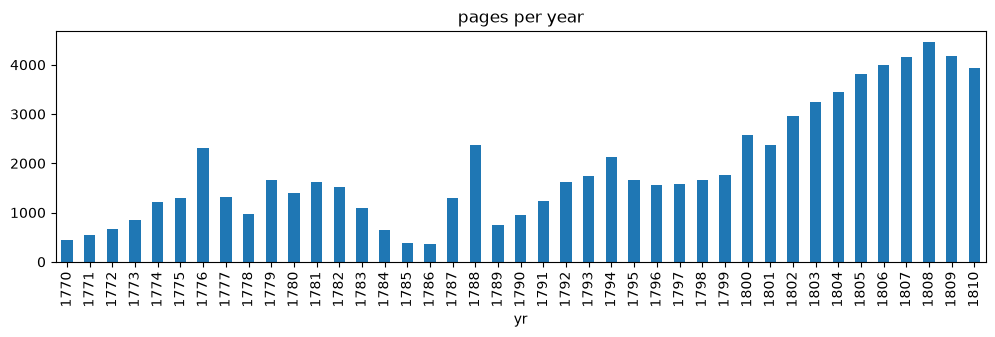

In [4]:
by_year=q("select yr, count(*) pages, count(distinct (lccn,d,edition_order)) issues, count(distinct lccn) lccns from news group by 1 order by 1")
display(by_year)
by_year.set_index('yr')['pages'].plot(kind='bar',figsize=(12,3),title='pages per year')
print(q("select min(issue_date)::date a,max(issue_date)::date b from news").iloc[0].tolist())
print('pages 1770-74:',int(by_year[by_year.yr.between(1770,1774)].pages.sum()),'(DATA.md: 3,720)')

## 3. Titles and places

In [5]:
tp=q("select lccn, any_value(newspaper_title) title, count(distinct newspaper_title) n_title_variants, any_value(place_of_publication) place, count(distinct place_of_publication) n_place_variants, min(yr) first_yr, max(yr) last_yr, count(*) pages from news group by 1 order by pages desc")
print(len(tp),'lccns; with >1 title/place variant:',int(((tp.n_title_variants>1)|(tp.n_place_variants>1)).sum()))
tp.head(20)

110 lccns; with >1 title/place variant: 0


,lccn,title,n_title_variants,place,n_place_variants,first_yr,last_yr,pages
0,sn83045242,The national intelligencer and Washington advertiser.,1,Washington City [D.C.],1,1800,1809,5575
1,sn84024012,Alexandria daily advertiser,1,Alexandria [Va.],1,1803,1808,4345
2,sn85025815,Norfolk gazette and publick ledger,1,Norfolk [Va.],1,1804,1810,3900
3,sn83025588,The New Hampshire gazette,1,Portsmouth [N.H.],1,1793,1810,3710
4,sn83025881,"Gazette of the United States, & Philadelphia daily advertiser.",1,Philadelphia [Pa.],1,1796,1800,3553
5,sn84024710,Virginia Argus,1,"Richmond, Va.",1,1797,1810,3216
6,sn84024736,The enquirer,1,"Richmond, Va.",1,1804,1810,2997
7,sn84024013,"Alexandria daily gazette, commercial & political",1,Alexandria [Va.],1,1808,1810,2934
8,sn83021127,"The Pennsylvania packet, or, The general advertiser",1,"Lancaster, Pa.;Philadelphia, Pa.",1,1777,1783,2893
9,sn82014782,The Kentucky gazette,1,Lexington [Ky.],1,1789,1803,2649


In [6]:
pl=q("select place_of_publication place, count(*) pages, count(distinct lccn) lccns from news group by 1 order by pages desc")
print(len(pl),'place strings'); pl.head(25)

48 place strings


,place,pages,lccns
0,Alexandria [Va.],9459,3
1,Philadelphia [Pa.],7268,6
2,"Richmond, Va.",6532,4
3,Washington City [D.C.],5575,1
4,Portsmouth [N.H.],5532,3
5,New-York [N.Y.],4153,6
6,Norfolk [Va.],3900,1
7,"Portsmouth, N.H.",3862,8
8,Lexington [Ky.],3773,3
9,"Lancaster, Pa.;Philadelphia, Pa.",2893,1


In [7]:
# state macro copied from prototypes/code/02-migration-land/query.sql (paperst); used for the land-ad breakdown too
con.sql("""create or replace macro paperst(p) as case when p ilike '%Va.%' or p ilike '%Virginia%' then 'VA' when p ilike '%Pa.%' then 'PA' when p ilike '%N.H.%' then 'NH'
  when p ilike '%Md.%' then 'MD' when p ilike '%Del%' then 'DE' when p ilike '%N.J.%' then 'NJ' when p ilike '%N.Y.%' then 'NY' when p ilike '%Ky.%' then 'KY'
  when p ilike '%Me.%' then 'ME' when p ilike '%D.C.%' then 'DC' when p ilike '%Mass%' then 'MA' when p ilike '%Conn%' then 'CT' when p ilike '%Vt%' then 'VT'
  when p ilike '%Ohio%' then 'OH' when p ilike '%Tenn%' then 'TN' when p ilike '%S.C.%' then 'SC' when p ilike '%N.C.%' then 'NC' when p ilike '%Ga.%' then 'GA' when p ilike '%La.%' then 'LA' else null end""")
st=q("select paperst(place_of_publication) st, count(*) pages, count(distinct lccn) lccns from news group by 1 order by 2 desc")
print('places the macro cannot map to a state:', q("select count(distinct place_of_publication) n, sum(1) from news where paperst(place_of_publication) is null").n[0])
display(q("select place_of_publication, count(*) pages from news where paperst(place_of_publication) is null group by 1 order by 2 desc limit 15"))
st

places the macro cannot map to a state: 4


,place_of_publication,pages
0,"Newport, R.I.",1108
1,Providence [R.I.],1076
2,"Warren, R.I.",398
3,Newport [R.I.],316


,st,pages,lccns
0,VA,26130,16
1,NH,12649,25
2,PA,12208,13
3,NY,6279,11
4,DC,5575,1
5,KY,3926,4
6,NaN,2898,6
7,ME,2607,7
8,NJ,1749,2
9,CT,1731,4


## 4. OCR source mix (`RevX_OCR_text` vs `ca_ocr_text`)

In [8]:
display(q("select count(*) pages, sum(has_rx::int) has_revx, sum(has_ca::int) has_ca, sum((has_rx and has_ca)::int) has_both, sum((not has_rx and not has_ca)::int) has_neither, round(100*avg((not has_rx)::int),2) pct_revx_blank from news"))
q("""select yr, count(*) pages, round(100*avg(has_rx::int),1) pct_revx, round(100*avg(has_ca::int),1) pct_ca,
 round(median(len_rx)) med_len_revx, round(median(len_ca)) med_len_ca from news group by 1 order by 1""")

,pages,has_revx,has_ca,has_both,has_neither,pct_revx_blank
0,77793,76311.0,77787.0,76305.0,0.0,1.91


,yr,pages,pct_revx,pct_ca,med_len_revx,med_len_ca
0,1770,448,98.7,100.0,13830.0,13532.0
1,1771,546,98.4,100.0,15752.0,16045.0
2,1772,675,99.4,100.0,14941.0,15328.0
3,1773,846,98.7,100.0,15915.0,16562.0
4,1774,1205,97.9,100.0,18552.0,19750.0
5,1775,1286,99.4,100.0,15649.0,17340.0
6,1776,2319,99.7,100.0,10488.0,11382.0
7,1777,1320,99.5,100.0,10342.0,10948.0
8,1778,970,99.0,100.0,12902.0,13289.0
9,1779,1660,99.5,100.0,13691.0,14341.0


In [9]:
q("""select round(median(len_rx::double/nullif(len_ca,0)),2) median_ratio, round(quantile_cont(len_rx::double/nullif(len_ca,0),0.05),2) p05, round(quantile_cont(len_rx::double/nullif(len_ca,0),0.95),2) p95 from news""")

,median_ratio,p05,p95
0,0.98,0.53,1.14


## 5. Text length

,src,n,mn,p05,med,p95,mx,mchars
0,RevX,77527,0,6792.3,16951.0,28382.0,49042,1348.7
1,ca,77793,0,8973.2,18269.0,29876.8,47302,1448.2


pages with RevX < 500 chars: 1229


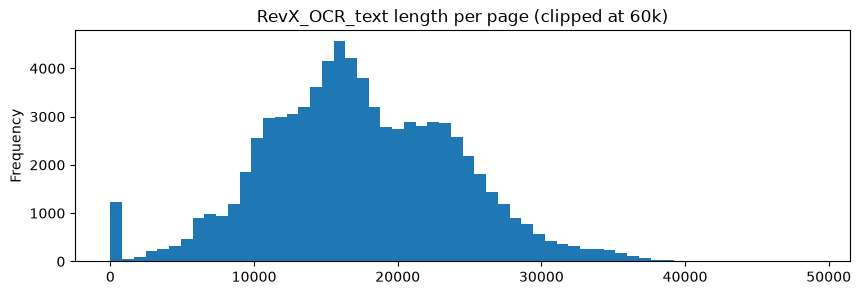

In [10]:
display(q("select 'RevX' src, count(len_rx) n, min(len_rx) mn, quantile_cont(len_rx,.05) p05, median(len_rx) med, quantile_cont(len_rx,.95) p95, max(len_rx) mx, round(sum(len_rx)/1e6,1) mchars from news union all select 'ca', count(len_ca), min(len_ca), quantile_cont(len_ca,.05), median(len_ca), quantile_cont(len_ca,.95), max(len_ca), round(sum(len_ca)/1e6,1) from news"))
q("select len_rx from news where len_rx is not null").len_rx.clip(upper=60000).plot(kind='hist',bins=60,figsize=(10,3),title='RevX_OCR_text length per page (clipped at 60k)')
print('pages with RevX < 500 chars:',q("select count(*) n from news where len_rx<500").n[0])

## 6. Page number and edition

In [11]:
print(q("select Page, count(*) n from news group by 1 order by 1").T.to_string())
q("select edition_order, count(*) n from news group by 1 order by 1").T

         0      1      2      3    4    5    6    7   8   9   10  11  12  13  14  15  16
Page      1      2      3      4    5    6    7    8   9  10  11  12  13  14  15  16  17
n     19444  19390  18771  18740  578  520  137  128  17  17  16  16  10   5   2   1   1


,0,1,2,3
edition_order,1,2,3,6
n,76952,836,1,4


## 7. Image fields for B (`jpeg2000_url`, `pdf_url`, `thumbnail_url`, `Web_URL`, page no.)
Pattern = digits replaced by `#`, lccn by `<lccn>`, to see the URL shape.

In [12]:
fields=['Web_URL','thumbnail_url','jpeg2000_url','pdf_url','ca_ocr_url']
rows=[]
for f in fields:
    r=q(f"select count(*) n, sum(({f} is null)::int) nulls, sum((trim({f})='')::int) blank, count(distinct {f}) distinct_urls from news").iloc[0]
    rows.append(dict(field=f,**r.to_dict()))
display(pd.DataFrame(rows))
for f in fields:
    print('\n',f); display(q(f"""select regexp_replace(regexp_replace({f},'sn[0-9]+','<lccn>'),'[0-9]+','#','g') pattern, count(*) n, any_value({f}) example from news group by 1 order by 2 desc limit 5"""))

,field,n,nulls,blank,distinct_urls
0,Web_URL,77793.0,0.0,0.0,19445.0
1,thumbnail_url,77793.0,0.0,0.0,77793.0
2,jpeg2000_url,77793.0,0.0,0.0,77793.0
3,pdf_url,77793.0,0.0,0.0,77793.0
4,ca_ocr_url,77793.0,0.0,0.0,77793.0



 Web_URL


,pattern,n,example
0,https://www.loc.gov/item/<lccn>/#-#-#/ed-#/,77793,https://www.loc.gov/item/sn82014385/1809-07-08/ed-1/



 thumbnail_url


,pattern,n,example
0,https://tile.loc.gov/image-services/iiif/service:ndnp:vi:batch_vi_flyingsquirrels_ver#:data:<lccn>:#:#:#/full/pct:#....,8919,https://tile.loc.gov/image-services/iiif/service:ndnp:vi:batch_vi_flyingsquirrels_ver03:data:sn84024011:00414215981:...
1,https://tile.loc.gov/image-services/iiif/service:ndnp:dlc:batch_dlc_annegreen_ver#:data:<lccn>:print:#:#/full/pct:#....,4918,https://tile.loc.gov/image-services/iiif/service:ndnp:dlc:batch_dlc_annegreen_ver02:data:sn82016139:print:1775010201...
2,https://tile.loc.gov/image-services/iiif/service:ndnp:dlc:batch_dlc_bowden_ver#:data:<lccn>:print:#:#/full/pct:#.#/#...,4905,https://tile.loc.gov/image-services/iiif/service:ndnp:dlc:batch_dlc_bowden_ver04:data:sn83020494:print:1776061801:00...
3,https://tile.loc.gov/image-services/iiif/service:ndnp:vi:batch_vi_alpina_ver#:data:<lccn>:#:#:#/full/pct:#.#/#/defau...,3884,https://tile.loc.gov/image-services/iiif/service:ndnp:vi:batch_vi_alpina_ver01:data:sn85025815:00542866573:180407170...
4,https://tile.loc.gov/image-services/iiif/service:ndnp:nhd:batch_nhd_avalon_ver#:data:<lccn>:#:#:#/full/pct:#.#/#/def...,3710,https://tile.loc.gov/image-services/iiif/service:ndnp:nhd:batch_nhd_avalon_ver02:data:sn83025588:00517010753:1793041...



 jpeg2000_url


,pattern,n,example
0,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_flyingsquirrels_ver#/data/<lccn>/#/#/#.jp#,8919,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_flyingsquirrels_ver03/data/sn84024011/00414215981/180...
1,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_annegreen_ver#/data/<lccn>/print/#/#.jp#,4918,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_annegreen_ver02/data/sn82016139/print/1775010201/00...
2,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_bowden_ver#/data/<lccn>/print/#/#.jp#,4905,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_bowden_ver04/data/sn83020494/print/1776061801/0001.jp2
3,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_alpina_ver#/data/<lccn>/#/#/#.jp#,3884,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_alpina_ver01/data/sn85025815/00542866573/1804071701/0...
4,https://tile.loc.gov/storage-services/service/ndnp/nhd/batch_nhd_avalon_ver#/data/<lccn>/#/#/#.jp#,3710,https://tile.loc.gov/storage-services/service/ndnp/nhd/batch_nhd_avalon_ver02/data/sn83025588/00517010753/1793041601...



 pdf_url


,pattern,n,example
0,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_flyingsquirrels_ver#/data/<lccn>/#/#/#.pdf,8919,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_flyingsquirrels_ver03/data/sn84024011/00414215981/180...
1,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_annegreen_ver#/data/<lccn>/print/#/#.pdf,4918,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_annegreen_ver02/data/sn82016139/print/1775010201/00...
2,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_bowden_ver#/data/<lccn>/print/#/#.pdf,4905,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_bowden_ver04/data/sn83020494/print/1776061801/0001.pdf
3,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_alpina_ver#/data/<lccn>/#/#/#.pdf,3884,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_alpina_ver01/data/sn85025815/00542866573/1804071701/0...
4,https://tile.loc.gov/storage-services/service/ndnp/nhd/batch_nhd_avalon_ver#/data/<lccn>/#/#/#.pdf,3710,https://tile.loc.gov/storage-services/service/ndnp/nhd/batch_nhd_avalon_ver02/data/sn83025588/00517010753/1793041601...



 ca_ocr_url


,pattern,n,example
0,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_flyingsquirrels_ver#/data/<lccn>/#/#/#.xml,8919,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_flyingsquirrels_ver03/data/sn84024011/00414215981/180...
1,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_annegreen_ver#/data/<lccn>/print/#/#.xml,4918,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_annegreen_ver02/data/sn82016139/print/1775010201/00...
2,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_bowden_ver#/data/<lccn>/print/#/#.xml,4905,https://tile.loc.gov/storage-services/service/ndnp/dlc/batch_dlc_bowden_ver04/data/sn83020494/print/1776061801/0001.xml
3,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_alpina_ver#/data/<lccn>/#/#/#.xml,3884,https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_alpina_ver01/data/sn85025815/00542866573/1804071701/0...
4,https://tile.loc.gov/storage-services/service/ndnp/nhd/batch_nhd_avalon_ver#/data/<lccn>/#/#/#.xml,3710,https://tile.loc.gov/storage-services/service/ndnp/nhd/batch_nhd_avalon_ver02/data/sn83025588/00517010753/1793041601...


In [13]:
# does the image URL identify the page? (page-specific = distinct per page) and does it carry the page no. consistent with Page?
print(q("select count(*) pages, count(distinct jpeg2000_url) jp2_distinct, count(distinct pdf_url) pdf_distinct, count(distinct (lccn,d,edition_order,Page)) page_keys from news").iloc[0].to_dict())
print(q("select count(*) n_page_mismatch from news where try_cast(regexp_extract(jpeg2000_url,'seq-([0-9]+)',1) as int) is not null and try_cast(regexp_extract(jpeg2000_url,'seq-([0-9]+)',1) as int)<>Page").iloc[0].to_dict())
print(q("select count(*) n_dup_page_keys from (select 1 from news group by lccn,d,edition_order,Page having count(*)>1)").iloc[0].to_dict())

{'pages': 77793, 'jp2_distinct': 77793, 'pdf_distinct': 77793, 'page_keys': 77793}
{'n_page_mismatch': 0}
{'n_dup_page_keys': 0}


## 8. `block_level` — news blocks
`collection='chronicling_america'`. One row = one layout block (one ad is usually one block, per prototype 2). Pages in `block_level` are zero-indexed.

In [14]:
print(q(f"select collection, count(*) blocks from read_parquet('{BLOCK_GLOB}') group by 1 order by 2 desc",'block_level counts by collection'))
print(TIMES[-1])
NB=q(f"select count(*) n from read_parquet('{BLOCK_GLOB}') where collection='chronicling_america'",'news block count').n[0]; print('news blocks',NB, TIMES[-1])
bt=q(f"select block_type, count(*) blocks, round(100*count(*)/{NB},2) pct from read_parquet('{BLOCK_GLOB}') where collection='chronicling_america' group by 1 order by 2 desc",'block_type counts'); print(TIMES[-1]); bt

            collection    blocks
0      rev_war_pension  14135050
1  chronicling_america   4896340
2          smithsonian     15220
('block_level counts by collection', 2.9)


news blocks 4896340 ('news block count', 0.3)


('block_type counts', 1.0)


,block_type,blocks,pct
0,Text,4106093,83.86
1,SectionHeader,664939,13.58
2,PageHeader,36310,0.74
3,ListGroup,32949,0.67
4,Table,30882,0.63
5,Picture,15907,0.32
6,PageFooter,4296,0.09
7,ComplexRegion,2946,0.06
8,Footnote,1654,0.03
9,Caption,308,0.01


In [15]:
# one scan: per-page block counts + extent (max x1,y1) from block_bbox, news only; no text columns
q(f"""create or replace table bpages as select filename, page_number, count(*) blocks,
  sum((try_cast(block_bbox as DOUBLE[]) is null or len(try_cast(block_bbox as DOUBLE[]))<>4)::int) bad_bbox,
  max(try_cast(block_bbox as DOUBLE[])[3]) max_x1, max(try_cast(block_bbox as DOUBLE[])[4]) max_y1,
  min(try_cast(block_bbox as DOUBLE[])[1]) min_x0, min(try_cast(block_bbox as DOUBLE[])[2]) min_y0
  from read_parquet('{BLOCK_GLOB}') where collection='chronicling_america' group by 1,2""",'bpages scan')
print(TIMES[-1])
print(q("select count(*) block_pages, count(distinct filename) files, sum(blocks) blocks, sum(bad_bbox) bad_bbox, min(page_number) min_pg, max(page_number) max_pg from bpages").iloc[0].to_dict())
print(q("select round(median(blocks)) med_blocks_per_page, min(blocks) mn, max(blocks) mx from bpages").iloc[0].to_dict())
print(q("select blocks, count(*) from bpages where blocks<=3 group by 1 order by 1").T.to_string())

('bpages scan', 3.5)
{'block_pages': 77534.0, 'files': 19441.0, 'blocks': 4896340.0, 'bad_bbox': 0.0, 'min_pg': 0.0, 'max_pg': 15.0}
{'med_blocks_per_page': 56.0, 'mn': 1.0, 'mx': 2054.0}
                 0  1   2
blocks           1  2   3
count_star()  1226  8  18


In [16]:
# bbox format: sample + numeric ranges
display(q(f"select block_bbox, block_id, block_type from read_parquet('{BLOCK_GLOB}') where collection='chronicling_america' limit 5",'bbox sample'))
q("select round(min(min_x0)) min_x0, round(min(min_y0)) min_y0, round(median(max_x1)) med_max_x1, round(median(max_y1)) med_max_y1, round(quantile_cont(max_x1,.05)) p05_x1, round(quantile_cont(max_x1,.95)) p95_x1, round(quantile_cont(max_y1,.05)) p05_y1, round(quantile_cont(max_y1,.95)) p95_y1 from bpages")

,block_bbox,block_id,block_type
0,"[233.0, 212.0, 2197.0, 338.0]",/page/0/SectionHeader/0,SectionHeader
1,"[111.0, 364.0, 288.0, 412.0]",/page/0/Text/1,Text
2,"[763.0, 369.0, 1619.0, 421.0]",/page/0/Text/2,Text
3,"[2164.0, 382.0, 2308.0, 425.0]",/page/0/Text/3,Text
4,"[72.0, 447.0, 641.0, 603.0]",/page/0/Text/4,Text


,min_x0,min_y0,med_max_x1,med_max_y1,p05_x1,p95_x1,p05_y1,p95_y1
0,0.0,0.0,2911.0,4611.0,1719.0,4914.0,2634.0,8307.0


## 9. Join: block → page
`filename` = `<lccn>_<YYYY-MM-DD>_<edition>.pdf`; `page_number` zero-indexed, so `Page = page_number + 1` (checked below: pages table has min Page = 1?).

In [17]:
print('filename pattern check:',q("select regexp_matches(filename,'^sn[0-9]+_[0-9]{4}-[0-9]{2}-[0-9]{2}_[0-9]+\\.pdf$') ok, count(*) n from bpages group by 1").to_dict('records'))
con.sql("""create or replace table bkeys as select filename, page_number, blocks, max_x1, max_y1,
  split_part(filename,'_',1) lccn, split_part(filename,'_',2) d, try_cast(split_part(split_part(filename,'_',3),'.',1) as bigint) edition_order, page_number+1 Page from bpages""")
j=q("""select count(*) block_pages, count(n.Page) matched, count(*)-count(n.Page) unmatched_block_pages from bkeys b left join news n using (lccn,d,edition_order,Page)""",'join blocks->pages')
display(j)
print('block pages that do not join (all of them):'); display(q("select b.filename, b.page_number, b.blocks from bkeys b left join news n using (lccn,d,edition_order,Page) where n.Page is null order by 1,2"))
print('pages without blocks that have NULL RevX_OCR_text:',q("select count(*) n, sum((n.len_rx is null)::int) rx_null from news n left join bkeys b using (lccn,d,edition_order,Page) where b.Page is null").iloc[0].to_dict())
r=q("""select count(*) pages, count(b.Page) with_blocks, count(*)-count(b.Page) pages_without_blocks from news n left join bkeys b using (lccn,d,edition_order,Page)""")
display(r)
display(q("select yr, count(*) pages, count(b.Page) with_blocks from news n left join bkeys b using (lccn,d,edition_order,Page) group by 1 order by 1").assign(missing=lambda x:x.pages-x.with_blocks).query('missing>0'))
# is the zero-index assumption right? compare matched count with page_number unshifted
print('if page_number were 1-indexed, matches would be:',q("select count(*) n from bkeys b join news n on n.lccn=b.lccn and n.d=b.d and n.edition_order=b.edition_order and n.Page=b.page_number").n[0])
print('width/height columns in any table:', [c for c in con.sql(f"describe select * from read_parquet('{BLOCK_GLOB}')").df().column_name if any(k in c.lower() for k in ('width','height','dim','size'))] , '(news pages table columns scanned above: none)')

filename pattern check: [{'ok': False, 'n': 4}, {'ok': True, 'n': 77530}]


,block_pages,matched,unmatched_block_pages
0,77534,77527,7


block pages that do not join (all of them):


,filename,page_number,blocks
0,parse_backup_0,0,2054
1,parse_backup_0,1,2014
2,parse_backup_0,2,1795
3,parse_backup_0,3,1893
4,sn83025523_1793-04-22_1.pdf,1,55
5,sn84038113_1804-11-10_1.pdf,0,63
6,sn84038113_1804-11-10_1.pdf,1,25


pages without blocks that have NULL RevX_OCR_text: {'n': 266.0, 'rx_null': 266.0}


,pages,with_blocks,pages_without_blocks
0,77793,77527,266


,yr,pages,with_blocks,missing
1,1771,546,545,1
2,1772,675,674,1
3,1773,846,843,3
4,1774,1205,1199,6
5,1775,1286,1282,4
6,1776,2319,2314,5
7,1777,1320,1316,4
8,1778,970,964,6
9,1779,1660,1657,3
10,1780,1406,1402,4


if page_number were 1-indexed, matches would be: 58106


width/height columns in any table: [] (news pages table columns scanned above: none)


In [18]:
# page-size proxy: max block x1/y1 per page. How stable is it (so area % = block area / (page extent proxy) is usable)?
q("select round(quantile_cont(max_x1,.5)) x_med, round(quantile_cont(max_x1,.1)) x_p10, round(quantile_cont(max_x1,.9)) x_p90, round(quantile_cont(max_y1,.5)) y_med, round(quantile_cont(max_y1,.1)) y_p10, round(quantile_cont(max_y1,.9)) y_p90 from bkeys")

,x_med,x_p10,x_p90,y_med,y_p10,y_p90
0,2911.0,1808.0,4663.0,4611.0,2876.0,7664.0


## 10. Land-sale blocks (prototype 2 rule, run on `block_level` text)
Rule from `prototypes/code/02-migration-land/query.sql` line 51 (acreage + sale wording), applied to lower-cased `block_text`:
`(\d+ acres | tract of land | lands? for sale)` AND `(for sale | to be sold | will be sold | at private sale | public sale)`.
Prototype ran it on NER-table blocks (22,435 hits); here on `block_level` (all news blocks), so counts may differ.

In [19]:
LAND_RE_A=r"\d+ acres|tract of land|lands? for sale"
LAND_RE_B=r"for sale|to be sold|will be sold|at private sale|public sale"
q(f"""create or replace table land as select filename, page_number, block_id, block_type, block_bbox, block_text, length(block_text) len
  from read_parquet('{BLOCK_GLOB}') where collection='chronicling_america'
  and regexp_matches(lower(block_text),'{LAND_RE_A}') and regexp_matches(lower(block_text),'{LAND_RE_B}')""",'land-sale block scan')
print(TIMES[-1]); print('land-sale blocks (raw scan):',q("select count(*) n from land").n[0],'| of which in the non-newspaper file `parse_backup_0`:',q("select count(*) n from land where filename not like 'sn%'").n[0])
con.sql("delete from land where filename not like 'sn%'")  # parse_backup_0 is not a newspaper file (see section 9)
print('land-sale blocks (newspaper files only):',q("select count(*) n from land").n[0],'(prototype: 22,435)')
con.sql("""create or replace table land2 as select l.*, split_part(filename,'_',1) lccn, split_part(filename,'_',2) d, year(try_cast(split_part(filename,'_',2) as date)) yr,
  try_cast(split_part(split_part(filename,'_',3),'.',1) as bigint) edition_order, page_number+1 Page from land l""")
con.sql("""create or replace table papers as select lccn, any_value(newspaper_title) title, any_value(place_of_publication) place from news group by lccn""")
print('land blocks whose lccn is not in the pages table:',q("select count(*) n from land2 where lccn not in (select lccn from papers)").n[0])
print('land blocks whose page is not in the pages table:',q("select count(*) n from land2 l left join news n using (lccn,d,edition_order,Page) where n.Page is null").n[0])

('land-sale block scan', 25.5)
land-sale blocks (raw scan): 26178 | of which in the non-newspaper file `parse_backup_0`: 61
land-sale blocks (newspaper files only): 26117 (prototype: 22,435)
land blocks whose lccn is not in the pages table: 0
land blocks whose page is not in the pages table: 2


,yr,land_blocks,pages,all_pages,land_blocks_per_100_pages
0,1770,125,66,448,27.9
1,1771,159,103,546,29.1
2,1772,215,128,675,31.9
3,1773,499,215,846,59.0
4,1774,610,260,1205,50.6
5,1775,336,206,1286,26.1
6,1776,501,290,2319,21.6
7,1777,392,241,1320,29.7
8,1778,156,118,970,16.1
9,1779,369,252,1660,22.2


<Axes: title={'center': 'land-sale blocks per year'}, xlabel='yr'>

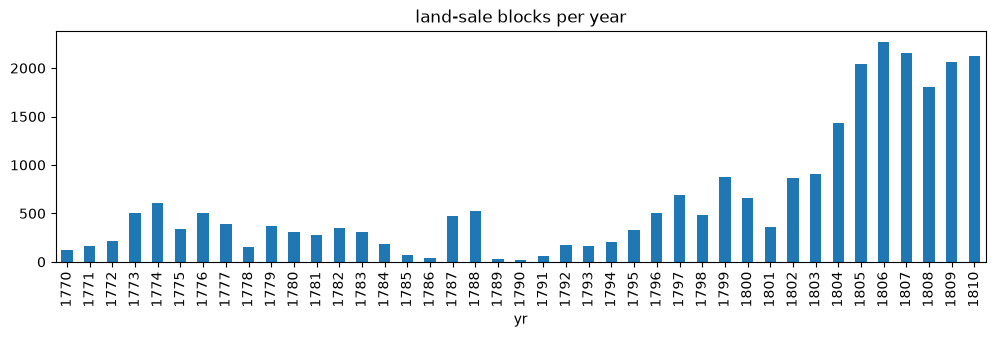

In [20]:
by_yr=q("select yr, count(*) land_blocks, count(distinct (lccn,d,edition_order,Page)) pages from land2 group by 1 order by 1")
by_yr=by_yr.merge(by_year[['yr','pages']].rename(columns={'pages':'all_pages'}),on='yr',how='right').fillna(0)
by_yr['land_blocks_per_100_pages']=(100*by_yr.land_blocks/by_yr.all_pages).round(1)
display(by_yr); by_yr.set_index('yr')['land_blocks'].plot(kind='bar',figsize=(12,3),title='land-sale blocks per year')

In [21]:
bp=q("""select p.title, p.place, paperst(p.place) st, count(*) land_blocks from land2 l join papers p using (lccn) group by all order by 4 desc""")
print(len(bp),'titles with >=1 land block'); display(bp.head(20))
display(bp.groupby('st',dropna=False).land_blocks.sum().sort_values(ascending=False).rename('land_blocks').to_frame().assign(pct=lambda x:(100*x.land_blocks/x.land_blocks.sum()).round(1)))

96 titles with >=1 land block


,title,place,st,land_blocks
0,Virginia Argus,"Richmond, Va.",VA,3303
1,The national intelligencer and Washington advertiser.,Washington City [D.C.],DC,2668
2,The enquirer,"Richmond, Va.",VA,2429
3,"Gazette of the United States, & Philadelphia daily advertiser.",Philadelphia [Pa.],PA,1891
4,The Virginia gazette,Williamsburg [Va.],VA,1475
5,Alexandria daily advertiser,Alexandria [Va.],VA,1457
6,"Alexandria daily gazette, commercial & political",Alexandria [Va.],VA,1397
7,Norfolk gazette and publick ledger,Norfolk [Va.],VA,1083
8,The Kentucky gazette,Lexington [Ky.],KY,847
9,Kentucky gazette and general advertiser,Lexington [Ky.],KY,788


,land_blocks,pct
st,,
VA,13353,51.1
PA,3774,14.5
DC,2668,10.2
KY,1725,6.6
NY,1256,4.8
NH,1167,4.5
NJ,568,2.2
ME,557,2.1
NaN,500,1.9


In [22]:
bty=q("select block_type, count(*) land_blocks, round(median(len)) med_chars, round(quantile_cont(len,.9)) p90_chars from land2 group by 1 order by 2 desc")
bty=bty.merge(bt[['block_type','blocks']],on='block_type',how='left'); bty['pct_of_all_blocks_of_type']=(100*bty.land_blocks/bty.blocks).round(2); display(bty)
q("select yr//10*10 dec, block_type, count(*) n from land2 group by 1,2 order by 1,3 desc")

,block_type,land_blocks,med_chars,p90_chars,blocks,pct_of_all_blocks_of_type
0,Text,23342,699.0,1660.0,4106093,0.57
1,SectionHeader,2653,15.0,36.0,664939,0.40
2,ListGroup,54,1625.0,4781.0,32949,0.16
3,ComplexRegion,51,6146.0,19539.0,2946,1.73
4,Table,17,993.0,3814.0,30882,0.06


,dec,block_type,n
0,1770,Text,3335
1,1770,SectionHeader,24
2,1770,Table,2
3,1770,ComplexRegion,1
4,1780,Text,2450
5,1780,SectionHeader,87
6,1780,ListGroup,19
7,1780,ComplexRegion,9
8,1780,Table,2
9,1790,Text,3090


In [23]:
# 10 reproducible samples (ordered by hash), with the join to the page and image URL
s=q("""select l.lccn, p.place, l.d, l.edition_order ed, l.Page, l.block_id, l.block_type, l.block_bbox, n.jpeg2000_url, substr(replace(l.block_text,chr(10),' '),1,350) snippet, l.len
 from land2 l left join papers p using (lccn) left join news n using (lccn,d,edition_order,Page)
 order by hash(l.filename||l.block_id) limit 10""")
for i,r in s.iterrows(): print(f"[{i}] {r.lccn} {r.place} {r.d} ed{r.ed} p{r.Page} {r.block_type} bbox={r.block_bbox} len={r.len}\n    {r.jpeg2000_url}\n    {r.snippet}\n")

[0] sn84024736 Richmond, Va. 1808-02-04 ed1 p4 Text bbox=[1663.0, 2528.0, 2421.0, 2777.0] len=1825
    https://tile.loc.gov/storage-services/service/ndnp/vi/batch_vi_loons_ver01/data/sn84024736/00414183815/1808020401/0361.jp2
    VALUABLE LAND FOR SALE.—On Wednesday the 10th day of February next, will be exposed to sale, to the highest bidder, for ready money, at Goodland court-house, the tract of LAND whereon Edward Bolling at present resides, lying on James river, in the county of Goochland, about three miles above the court-house, containing by estimation one thousand ac

[1] sn82014385 Wilmington [Del.] 1809-07-26 ed1 p1 Text bbox=[720.0, 3010.0, 1292.0, 3669.0] len=1010
    https://tile.loc.gov/storage-services/service/ndnp/deu/batch_deu_kedavra_ver01/data/sn82014385/00271740232/1809072601/0094.jp2
    BY Virtue of an Order of the Orphan's Court for the said County of New-Castle, will be exposed to sale, at Public Vendue, on Monday, the 7th day of August next, at 2 o'clock in the 

### Known false-positive patterns (rule is loose: keyword, not classification)
Check against the samples above and tests below.

In [24]:
# how many hits are only the generic '\d+ acres' (no 'tract of land' / 'land for sale') - e.g. rent/lease/lost-cattle ads - and how many are very long (a whole column of mixed ads)
x=q("""select count(*) n,
 sum((regexp_matches(lower(block_text),'tract of land|lands? for sale'))::int) with_tract_or_landforsale,
 sum((not regexp_matches(lower(block_text),'tract of land|lands? for sale'))::int) acres_only,
 sum((len>3000)::int) over_3000_chars, sum((len>8000)::int) over_8000_chars,
 sum((regexp_matches(lower(block_text),'\\b(?:to let|to rent|for rent|lease)\\b'))::int) mentions_rent_lease,
 sum((regexp_matches(lower(block_text),'sheriff|execution|trustee|administrator|commissioner|decree'))::int) legal_sale_wording
 from land"""); display(x)

,n,with_tract_or_landforsale,acres_only,over_3000_chars,over_8000_chars,mentions_rent_lease,legal_sale_wording
0,26117,12980.0,13137.0,517.0,33.0,917.0,3373.0


## 11. Timings and assertions

In [25]:
display(pd.DataFrame(TIMES,columns=['query','seconds']))
print('total seconds',round(sum(t for _,t in TIMES),1))

,query,seconds
0,load pages (metadata+lengths),62.0
1,"select count(*) pages, count(distinct lccn) lccns, count(dis",0.0
2,"select sum((lccn is null)::int) lccn,sum((newspaper_title is",0.0
3,select has_rx from news,0.0
4,select has_ca from news,0.0
5,"select yr, count(*) pages, count(distinct (lccn,d,edition_or",0.0
6,"select min(issue_date)::date a,max(issue_date)::date b from",0.0
7,"select lccn, any_value(newspaper_title) title, count(distinc",0.0
8,"select place_of_publication place, count(*) pages, count(dis",0.0
9,"select paperst(place_of_publication) st, count(*) pages, cou",0.0


total seconds 99.0


In [26]:
# assertions: only what the notebook relies on
assert q("select count(*) n from news").n[0]==77793, 'page count differs from DATA.md'
assert q("select count(distinct lccn) n from news").n[0]==110
assert q("select count(distinct (lccn,d,edition_order)) n from news").n[0]==19445
assert q("select count(*) n from news where Page is null or lccn is null or issue_date is null").n[0]==0
assert q("select count(*) n from (select 1 from news group by lccn,d,edition_order,Page having count(*)>1)").n[0]==0, 'page key not unique'
assert q("select sum(bad_bbox) n from bpages").n[0]==0, 'bbox not always 4 numbers'
assert q("select count(*) n from bkeys").n[0]>0 and NB==4896340
assert q("select count(*) n from bkeys b left join news n using (lccn,d,edition_order,Page) where n.Page is null and filename not like 'sn%'").n[0]==4, 'expected 4 parse_backup_0 pages'
assert q("select count(*) n from bkeys b left join news n using (lccn,d,edition_order,Page) where n.Page is null and filename like 'sn%'").n[0]==3, 'expected 3 real news block pages missing from pages table'
assert q("select count(*) n from news n left join bkeys b using (lccn,d,edition_order,Page) where b.Page is null and n.len_rx is not null").n[0]==0, 'pages without blocks should be exactly the null-RevX pages'
assert q("select count(*) n from land2 where lccn not in (select lccn from papers)").n[0]==0
assert q("select count(*) n from land2").n[0]>0
print('all assertions passed')

all assertions passed


## 12. Findings (for B) and contradictions with `docs/DATA.md`
**Findings**
1. Pages table matches DATA.md: 77,793 pages, 19,445 issues, 110 lccns, 105 titles, 48 place strings (many are the same city spelled two ways, e.g. `Portsmouth [N.H.]` vs `Portsmouth, N.H.`); 3,720 pages 1770-74. Page key (lccn, date, edition, Page) is unique. Sources: 99% have `RevX_OCR_text`; 1,482 are null or blank (1.91%; 266 null + 1,216 whitespace), median RevX/ca length ratio 0.98 (p05-p95 0.53-1.14), as in DATA.md.
2. Image fields are complete: `jpeg2000_url`, `pdf_url`, `thumbnail_url`, `ca_ocr_url` are never null and are unique per page (77,793 distinct); `Web_URL` is per issue (19,445). The `.jp2` and `.pdf` are page-level files in LoC batch folders (several batch folders); `Page` is 1-indexed and always agrees with the file sequence in the URL.
3. `block_level` news = 4,896,340 blocks (of 19.0M: pension 14.1M, news 4.9M, Smithsonian 15k). 84% `Text`, 14% `SectionHeader`; median 56 blocks per page. `block_bbox` is a string `[x0, y0, x1, y1]` in pixels, always 4 numbers (0 bad), minimum x0, y0 = 0.
4. Join works: `filename` = `<lccn>_<YYYY-MM-DD>_<edition>.pdf`, `Page = page_number + 1` (the unshifted join matches only 58,106). 77,527 of 77,793 pages have blocks; the 266 without are exactly the 266 null-`RevX_OCR_text` pages. Left over: 3 real news pages in blocks but not in the pages table (sn84038113 1804-11-10 pp.1-2, sn83025523 1793-04-22 p.2), and 4 pages of a non-newspaper filename `parse_backup_0` (7,756 blocks, 61 land hits; excluded).
5. No page width/height anywhere (pages, blocks, page_level, file_level have none). A proxy is the max block x1/y1 per page: median 2,911 x 4,611 px, but p10-p90 is 1,808-4,663 x 2,876-7,664, so scans differ a lot in size. Area % needs either the per-page extent proxy (understates blank margins) or the VLM bucket `.chunks.json` (width/height).
6. Land-sale rule on blocks: 26,117 hits in 96 titles (prototype 22,435 on NER blocks, so not the same set). By type: Text 89.4%, SectionHeader 10.2% (a 15-char header like `LAND FOR SALE` flags a different block than the ad body, so header + body are two hits), ListGroup/ComplexRegion/Table <0.5% together. 1805-1810 is ~2,000 blocks/year (about 50 per 100 pages); 1789-1791 almost none (2-5 per 100 pages). Place: VA 51%, PA 14.5%, DC 10%, KY 6.6%, NY 4.8%, NH 4.5%; skew follows the corpus (Virginia Argus alone 3,303).
7. False positives: half of the hits (13,157) match only `\d+ acres` with no 'tract of land / land for sale'; 917 mention rent/lease, 3,382 use court/estate wording (sheriff, trustee, administrator...), 517 blocks exceed 3,000 chars (likely several ads merged); blocks can start mid-ad (sample 5 begins 'And may be entered upon...'), so one ad can be several blocks. Rule matches the first block of land-sale wording, not a classified ad.
8. Timing (remote, no token): pages load 62 s (full-text length scan of 6 shards); block_level collection counts 3 s, type counts 2 s, per-page bbox scan 3 s, land-sale regex scan 26 s; whole notebook about 100 s of query time. HF answered HTTP 429 after several quick re-runs, so the notebook sets DuckDB retries.

**Contradicts or adds to DATA.md**
- DATA.md says `RevX_OCR_results` has 19,046,610 blocks "all collections": confirmed, and the "11.8M" note is not needed (news is 4.9M, pension 14.1M).
- DATA.md lists the news page table without noting that its image fields are always populated: fine, nothing contradicted. It does not mention the `parse_backup_0` filename (7,756 non-news blocks under `chronicling_america`); filter `filename like 'sn%'`.
- DATA.md says 'B: ad blocks, text + area on page' and 'bbox raw px'; true, but width/height are not in the tables (only in the bucket), see 5.
- DATA.md's null note (`RevX_OCR_text` null/blank on ~1.9%) holds: 1.91%. The `Prototype 22,435 land-sale blocks` figure does not reproduce on block_level (26,117).
- Proposed `config.py` pin: `RevX_OCR_results` revision `92477706d19db4dcd0c425e01e1ff85a209a8269`, `block_level/train-0000{0..26}-of-00027.parquet`, filter `collection='chronicling_america'`.